# Customer Churn Prediction (Telco)

**Goal:** predict which telecom customers are likely to leave (churn), so a company could target them with retention offers.

**Dataset:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (Kaggle). Download `WA_Fn-UseC_-Telco-Customer-Churn.csv` and place it in the same folder as this notebook.

**Workflow:** cleaning -> EDA -> feature engineering -> handling class imbalance -> comparing 4 models with cross-validation -> hyperparameter tuning -> final evaluation -> feature importance -> save model.

In [12]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, precision_score, recall_score, f1_score)
from sklearn.inspection import permutation_importance

from churn_utils import build_pipeline, add_features

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load and inspect the data

In [13]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Data cleaning

- `customerID` is just an identifier, so it is dropped (it carries no signal).
- `TotalCharges` is stored as text because brand-new customers have a blank value. It is converted to numeric; the blanks become missing values that the pipeline fills with the median.
- The target `Churn` is converted from Yes/No to 1/0.

In [15]:
df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())

y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["Churn"])

Missing values per column:
TotalCharges    11
dtype: int64
Duplicate rows: 22


## 3. Exploratory data analysis (EDA)

Churn rate: 26.5%  (1869 of 7043 customers)


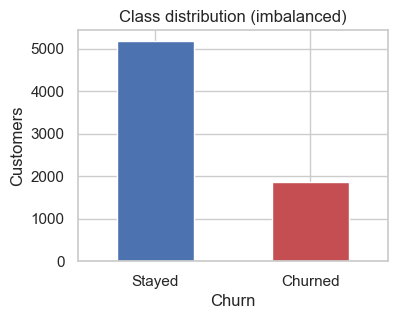

In [16]:
churn_rate = y.mean()
print(f"Churn rate: {churn_rate:.1%}  ({y.sum()} of {len(y)} customers)")

fig, ax = plt.subplots(figsize=(4, 3))
y.map({0: "Stayed", 1: "Churned"}).value_counts().plot(kind="bar", ax=ax, color=["#4c72b0", "#c44e52"])
ax.set_title("Class distribution (imbalanced)")
ax.set_ylabel("Customers")
plt.xticks(rotation=0)
plt.show()

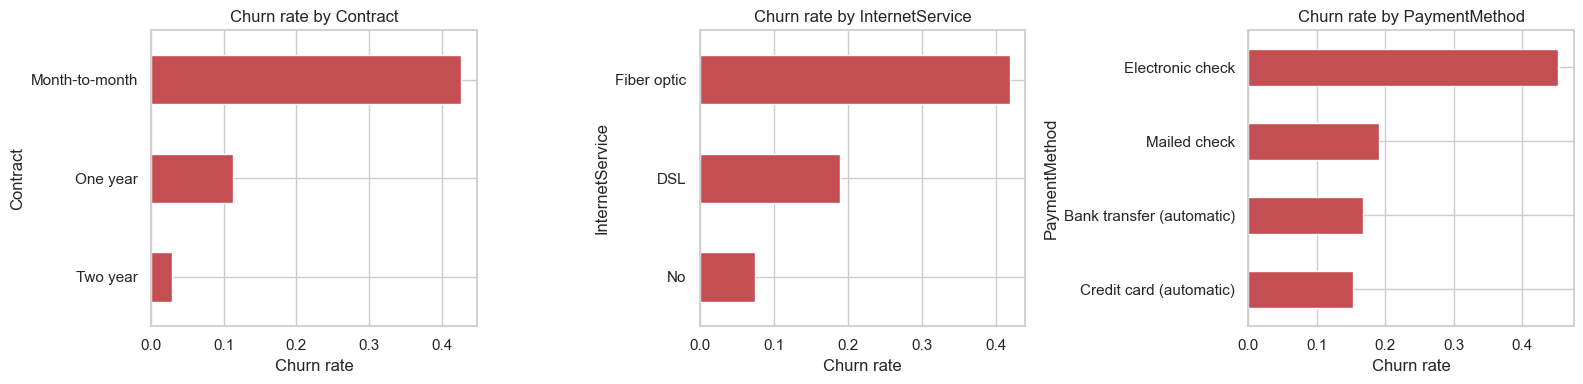

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rate = df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values()
    rate.plot(kind="barh", ax=ax, color="#c44e52")
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("Churn rate")
plt.tight_layout()
plt.show()

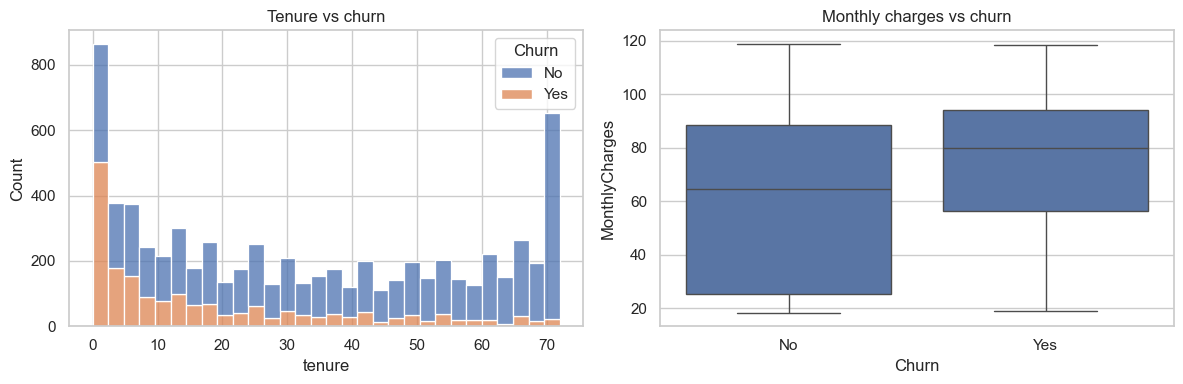

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[0], multiple="stack")
axes[0].set_title("Tenure vs churn")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly charges vs churn")
plt.tight_layout()
plt.show()

**Observations to write up in your README** (check them against your own plots):
fill in what you actually see, for example which contract type churns most, how tenure relates to churn, and whether higher monthly charges go with more churn.

## 4. Feature engineering

Two features are added inside the pipeline (see `churn_utils.py`):
- `num_addons`: number of add-on services a customer has (security, backup, protection, support, streaming).
- `is_new_customer`: 1 if tenure is 12 months or less.

Doing this inside the pipeline means the same logic is applied during training, testing, and in the web app.

In [19]:
engineered = add_features(X)
engineered.assign(Churn=y.values).groupby("is_new_customer")["Churn"].mean().rename("churn_rate")

is_new_customer
0    0.171299
1    0.474382
Name: churn_rate, dtype: float64

## 5. Train/test split and class imbalance

The split is **stratified** so train and test keep the same churn proportion. About a quarter of customers churn, so the classes are imbalanced. Plain accuracy would be misleading (always predicting "stayed" already scores ~73%), so models are compared on **recall, F1 and ROC-AUC**. Logistic Regression and Random Forest use `class_weight="balanced"` to give churners more weight.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
print("Baseline accuracy if we always predict 'stayed':", round(1 - y_test.mean(), 3))

Train: (5634, 19)  Test: (1409, 19)
Churn rate train/test: 0.265 0.265
Baseline accuracy if we always predict 'stayed': 0.735


## 6. Compare four models with 5-fold cross-validation

In [21]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for name, model in models.items():
    scores = cross_validate(build_pipeline(model), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"model": name, **{m: scores[f"test_{m}"].mean() for m in scoring}})

cv_results = pd.DataFrame(rows).set_index("model").round(3).sort_values("roc_auc", ascending=False)
cv_results

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Gradient Boosting,0.803,0.661,0.531,0.589,0.848
Logistic Regression,0.750,0.519,0.799,0.629,0.846
KNN,0.788,0.610,0.555,0.581,0.825
Random Forest,0.787,0.634,0.472,0.541,0.823


In [22]:
best_name = cv_results.index[0]
print("Best model by cross-validated ROC-AUC:", best_name)

Best model by cross-validated ROC-AUC: Gradient Boosting


## 7. Hyperparameter tuning

The best model from the comparison is tuned with `GridSearchCV`, optimising **F1** (it balances precision and recall, which matters for an imbalanced problem).

In [24]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "KNN": {"model__n_neighbors": [5, 11, 21, 31]},
    "Random Forest": {"model__n_estimators": [100, 200], "model__max_depth": [5, 10],
                      "model__min_samples_leaf": [5, 10]},
    "Gradient Boosting": {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1],
                          "model__max_depth": [2, 3]},
}

search = GridSearchCV(build_pipeline(models[best_name]), param_grids[best_name],
                      cv=cv, scoring="f1", n_jobs=1)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV F1:", round(search.best_score_, 3))
final_model = search.best_estimator_

Best params: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200}
Best CV F1: 0.59


## 8. Final evaluation on the held-out test set

In [25]:
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))

              precision    recall  f1-score   support

      Stayed       0.84      0.91      0.87      1035
     Churned       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409

ROC-AUC: 0.844


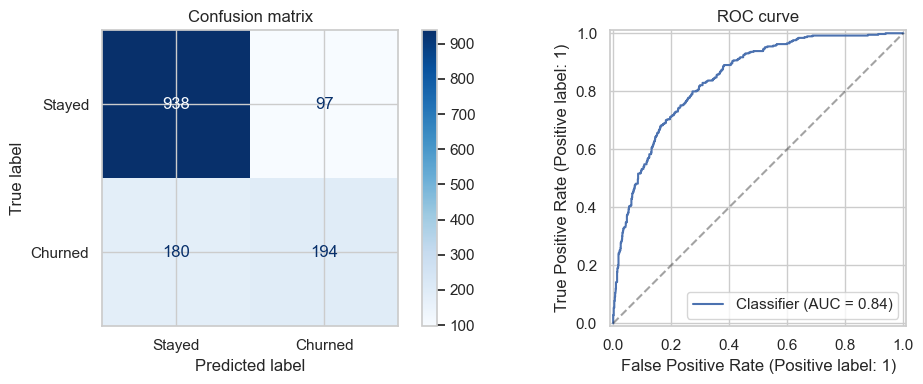

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Stayed", "Churned"], ax=axes[0], cmap="Blues")
axes[0].set_title("Confusion matrix")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set_title("ROC curve")
plt.tight_layout()
plt.show()

### Choosing a decision threshold

By default a customer is flagged as churn when the predicted probability is 0.5 or higher. In a retention campaign, **missing a churner (false negative) usually costs more than contacting someone who would have stayed (false positive)**, so a lower threshold can make sense. The table shows the trade-off.

In [27]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    pred = (y_proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred)})
pd.DataFrame(rows).round(3).set_index("threshold")

,precision,recall,f1
threshold,,,
0.3,0.527,0.757,0.621
0.4,0.600,0.671,0.634
0.5,0.667,0.519,0.583
0.6,0.733,0.374,0.496


## 9. What drives churn? (permutation importance)

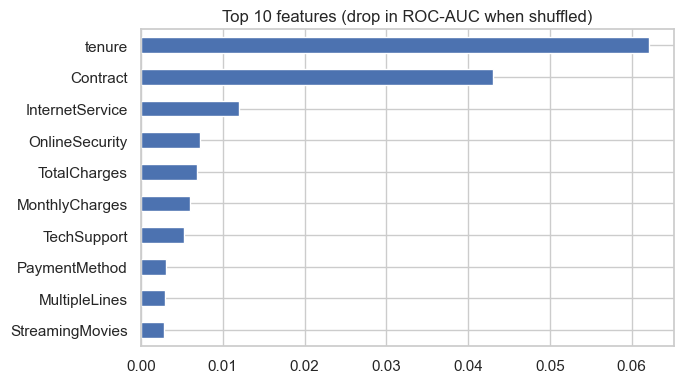

tenure             0.0621
Contract           0.0430
InternetService    0.0120
OnlineSecurity     0.0072
TotalCharges       0.0069
MonthlyCharges     0.0060
TechSupport        0.0053
PaymentMethod      0.0031
MultipleLines      0.0029
StreamingMovies    0.0028
dtype: float64

In [29]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(7, 4))
importance[::-1].plot(kind="barh", ax=ax, color="#4c72b0")
ax.set_title("Top 10 features (drop in ROC-AUC when shuffled)")
plt.tight_layout()
plt.show()
importance.round(4)

## 10. Save the trained model

In [30]:
joblib.dump(final_model, "churn_model.joblib")
print("Saved churn_model.joblib")

Saved churn_model.joblib


## 11. Summary (write this in your own words after running)

- Best model and its test-set metrics (precision, recall, F1, ROC-AUC):
- Top 3 features driving churn:
- What you would recommend a business do:
- Limitations and next steps (for example more features, SMOTE, XGBoost, probability calibration):